# WSN Lab 1 — Data Analysis & Visualization

Loads a raw serial-log CSV (real hardware, a parsed Wokwi dump, or for now the
synthetic sample), computes the descriptive statistics required in Section
7.3 of the lab guide, produces the plots required in Section 7.4, and writes
a cleaned dataset to `data/processed/`.

**To switch to real data later**: change `RAW_PATH` in the next cell to
whichever file `acquisition.ipynb` produced, then re-run the whole notebook —
nothing else needs to change.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW_PATH = "../data/raw/wokwi_serial_log.csv"   # <-- real capture from Jude's Wokwi run
FIG_DIR = "../figures"
PROCESSED_PATH = "../data/processed/cleaned_log.csv"
SAMPLE_RATE_HZ = 1.0   # matches the firmware's 1 Hz sampling loop

df = pd.read_csv(RAW_PATH)

# temp_raw / humidity / temp_cal are blank strings on INVALID rows -- coerce to NaN
for col in ["temp_raw", "humidity", "temp_cal"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# a simple elapsed-time column, since sample count already IS elapsed seconds at 1 Hz
df["t_seconds"] = df["sample"] / SAMPLE_RATE_HZ

df.head()

,sample,temp_raw,humidity,light,motion,temp_cal,temp_ma,temp_roc,status,valid,t_seconds
0,1,24.0,40.0,0.244,0,24.0,24.0,0.0,NORMAL,1,1.0
1,2,24.0,40.0,0.244,0,24.0,24.0,0.0,NORMAL,1,2.0
2,3,24.0,40.0,0.244,0,24.0,24.0,0.0,NORMAL,1,3.0
3,4,24.0,40.0,0.244,0,24.0,24.0,0.0,NORMAL,1,4.0
4,5,24.0,40.0,0.244,0,24.0,24.0,0.0,NORMAL,1,5.0


## Descriptive statistics (Section 7.3)

In [2]:
n_obs = len(df)
duration_s = df["t_seconds"].iloc[-1] - df["t_seconds"].iloc[0]
n_invalid = int((df["valid"] == 0).sum())
n_events = int((df["status"] == "HIGH_TEMP").sum() + (df["motion"] == 1).sum())

stats = pd.DataFrame({
    "temp_raw": df["temp_raw"].describe(),
    "humidity": df["humidity"].describe(),
    "light": df["light"].describe(),
}).T[["count", "mean", "min", "max", "std"]]

print(f"Observations           : {n_obs}")
print(f"Duration                : {duration_s:.0f} s  (~{duration_s/60:.1f} min)")
print(f"Invalid measurements    : {n_invalid}  ({n_invalid/n_obs*100:.1f}%)")
print(f"Detected events (HIGH_TEMP + motion): {n_events}")
print()
stats.round(3)

Observations           : 723
Duration                : 722 s  (~12.0 min)
Invalid measurements    : 0  (0.0%)
Detected events (HIGH_TEMP + motion): 90



,count,mean,min,max,std
temp_raw,723.0,23.183,-5.800,60.800,12.136
humidity,723.0,40.000,40.000,40.000,0.000
light,723.0,0.423,0.025,0.989,0.204


## Plot 1/5 — Temperature vs time

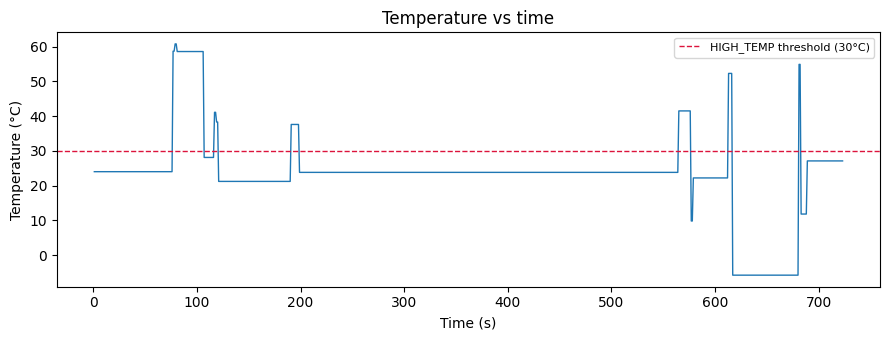

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(df["t_seconds"], df["temp_raw"], linewidth=1)
ax.axhline(30.0, color="crimson", linestyle="--", linewidth=1, label="HIGH_TEMP threshold (30°C)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature vs time")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/temp_vs_time.png", dpi=150)
plt.show()

## Plot 2/5 — Humidity vs time

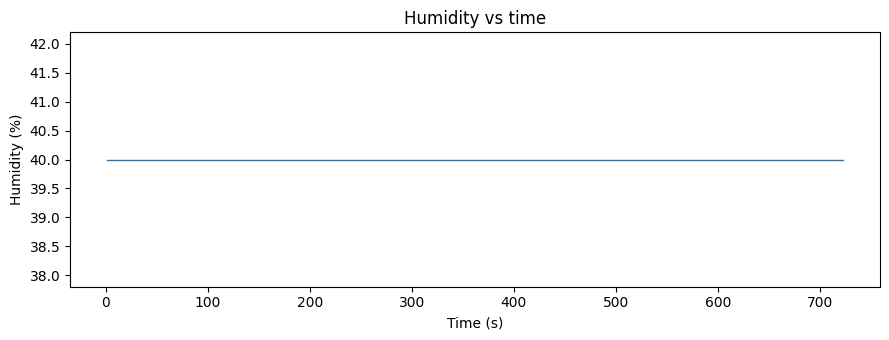

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(df["t_seconds"], df["humidity"], linewidth=1, color="tab:blue")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Humidity (%)")
ax.set_title("Humidity vs time")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/humidity_vs_time.png", dpi=150)
plt.show()

## Plot 3/5 — Raw vs filtered temperature (moving average)

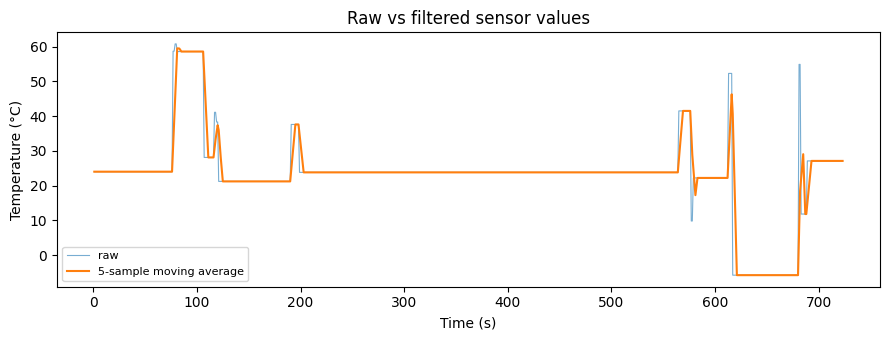

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(df["t_seconds"], df["temp_raw"], linewidth=0.8, alpha=0.6, label="raw")
ax.plot(df["t_seconds"], df["temp_ma"], linewidth=1.5, label="5-sample moving average")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Raw vs filtered sensor values")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/raw_vs_filtered_temp.png", dpi=150)
plt.show()

## Plot 4/5 — Light vs time

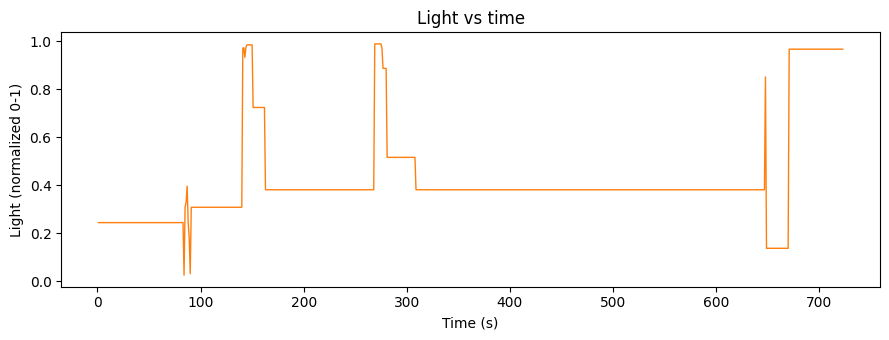

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(df["t_seconds"], df["light"], linewidth=1, color="tab:orange")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Light (normalized 0-1)")
ax.set_title("Light vs time")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/light_vs_time.png", dpi=150)
plt.show()

## Plot 5/5 (optional) — Motion events

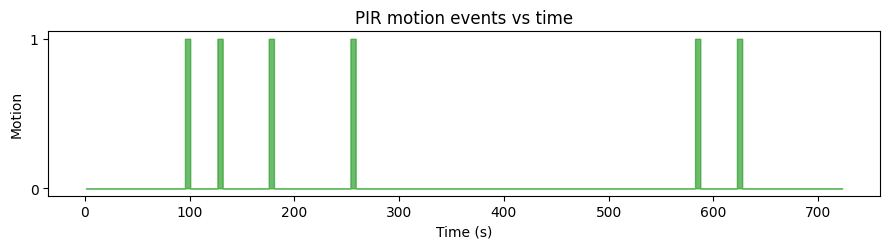

In [7]:
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.fill_between(df["t_seconds"], df["motion"], step="mid", color="tab:green", alpha=0.7)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion")
ax.set_yticks([0, 1])
ax.set_title("PIR motion events vs time")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/motion_events.png", dpi=150)
plt.show()

## Save the processed / cleaned dataset

Keeps every column, adds `t_seconds`, and keeps the `valid` flag rather than
silently dropping invalid rows (per the lab guide's safety note: "record
unexpected behavior rather than silently deleting measurements").

In [8]:
df.to_csv(PROCESSED_PATH, index=False)
print(f"Saved {len(df)} rows -> {PROCESSED_PATH}")

Saved 723 rows -> ../data/processed/cleaned_log.csv
